# 01 — Exploratory Data Analysis

Credit card fraud detection, ULB dataset: 284,807 transactions, 492 of them fraudulent.

The purpose of this notebook is narrow: work out what the data can and cannot support before any
modelling decisions get made. Three questions in particular:

1. **How severe is the imbalance, really?** This determines which metrics are meaningful.
2. **Do `Time` and `Amount` carry signal?** They are the only two non-anonymised columns, so they
   are the only place feature engineering is possible at all.
3. **Which PCA components separate the classes?** This feeds the interaction terms in `src/features.py`
   and gives error analysis somewhere to start.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data import load_raw, make_splits

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
REPORTS = Path.cwd().parent / "reports"

df = load_raw()
print(f"{df.shape[0]:,} transactions x {df.shape[1]} columns")
print(f"missing values: {int(df.isna().sum().sum())}")
print(f"duplicate rows: {int(df.duplicated().sum()):,}")
df.head()

284,807 transactions x 31 columns
missing values: 0


duplicate rows: 1,081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. The imbalance

The headline number is the whole reason this project exists. Stated as a percentage rather than a
count, because the count alone doesn't convey how badly it breaks the default metric.

legitimate : 284,315 (99.827%)
fraud      : 492 (0.173%)
imbalance ratio: 1 fraud per 578 legitimate transactions

A model that always predicts 'legitimate' scores 99.827% accuracy
and catches 0 of 492 frauds. That is why accuracy is not used anywhere in this project.


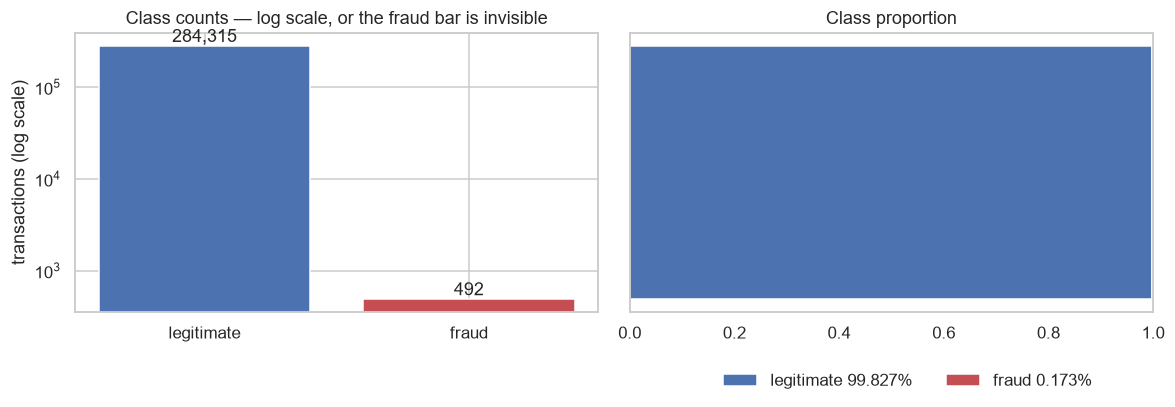

In [2]:
counts = df["Class"].value_counts().sort_index()
rate = df["Class"].mean()

print(f"legitimate : {counts.loc[0]:,} ({1 - rate:.3%})")
print(f"fraud      : {counts.loc[1]:,} ({rate:.3%})")
print(f"imbalance ratio: 1 fraud per {counts.loc[0] / counts.loc[1]:.0f} legitimate transactions")
print()
print(f"A model that always predicts 'legitimate' scores {1 - rate:.3%} accuracy")
print(f"and catches 0 of {counts.loc[1]} frauds. That is why accuracy is not used anywhere in this project.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["legitimate", "fraud"], counts.values, color=["#4c72b0", "#c44e52"])
axes[0].set_yscale("log")
axes[0].set_ylabel("transactions (log scale)")
axes[0].set_title("Class counts — log scale, or the fraud bar is invisible")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

axes[1].barh([""], [1 - rate], color="#4c72b0", label=f"legitimate {1-rate:.3%}")
axes[1].barh([""], [rate], left=[1 - rate], color="#c44e52", label=f"fraud {rate:.3%}")
axes[1].set_xlim(0, 1)
axes[1].set_title("Class proportion")
axes[1].legend(loc="center left", bbox_to_anchor=(0.15, -0.25), ncol=2, frameon=False)
axes[1].grid(False)
fig.tight_layout()
fig.savefig(REPORTS / "class_imbalance.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Amount

`Amount` is one of only two interpretable columns. It is heavily right-skewed, as transaction
amounts always are, so the interesting comparison is on a log scale.

In [3]:
legit = df.loc[df["Class"] == 0, "Amount"]
fraud = df.loc[df["Class"] == 1, "Amount"]

summary = pd.DataFrame({
    "legitimate": legit.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]),
    "fraud": fraud.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]),
}).round(2)
print(summary.to_string())
print()
print(f"median  legit ${legit.median():.2f}   fraud ${fraud.median():.2f}")
print(f"mean    legit ${legit.mean():.2f}   fraud ${fraud.mean():.2f}")
print(f"zero-amount transactions: legit {int((legit == 0).sum()):,}, fraud {int((fraud == 0).sum())}")

       legitimate    fraud
count   284315.00   492.00
mean        88.29   122.21
std        250.11   256.68
min          0.00     0.00
25%          5.65     1.00
50%         22.00     9.25
75%         77.05   105.89
95%        364.41   640.90
99%       1016.97  1357.43
max      25691.16  2125.87

median  legit $22.00   fraud $9.25
mean    legit $88.29   fraud $122.21
zero-amount transactions: legit 1,798, fraud 27


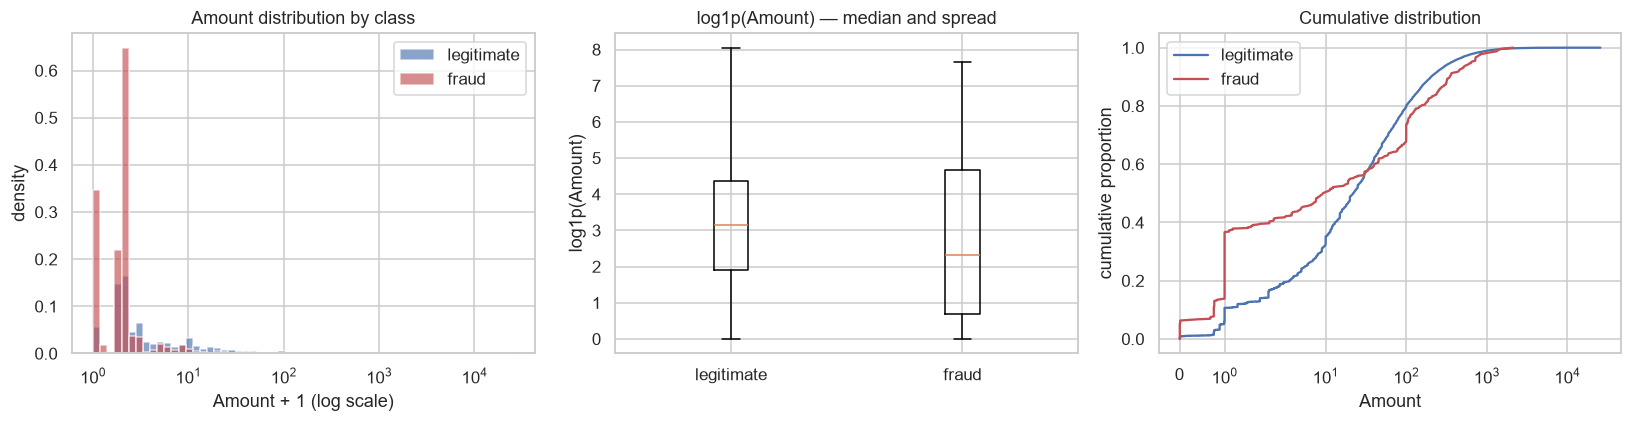

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

bins = np.logspace(0, np.log10(df["Amount"].max() + 1), 60)
axes[0].hist(legit + 1, bins=bins, density=True, alpha=0.65, label="legitimate", color="#4c72b0")
axes[0].hist(fraud + 1, bins=bins, density=True, alpha=0.65, label="fraud", color="#c44e52")
axes[0].set_xscale("log")
axes[0].set_xlabel("Amount + 1 (log scale)")
axes[0].set_ylabel("density")
axes[0].set_title("Amount distribution by class")
axes[0].legend()

data = [np.log1p(legit), np.log1p(fraud)]
axes[1].boxplot(data, tick_labels=["legitimate", "fraud"], showfliers=False)
axes[1].set_ylabel("log1p(Amount)")
axes[1].set_title("log1p(Amount) — median and spread")

ecdf_x = np.sort(fraud)
axes[2].plot(np.sort(legit), np.linspace(0, 1, len(legit)), label="legitimate", color="#4c72b0")
axes[2].plot(ecdf_x, np.linspace(0, 1, len(fraud)), label="fraud", color="#c44e52")
axes[2].set_xscale("symlog")
axes[2].set_xlabel("Amount")
axes[2].set_ylabel("cumulative proportion")
axes[2].set_title("Cumulative distribution")
axes[2].legend()

fig.tight_layout()
fig.savefig(REPORTS / "amount_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Time

`Time` is seconds elapsed since the first transaction in the file, spanning just under two days.
As a raw model input that is close to a row index — a tree can split on "the second day", which
generalises to nothing. The useful transform is hour-of-day.

Time spans 48.0 hours (2.00 days)


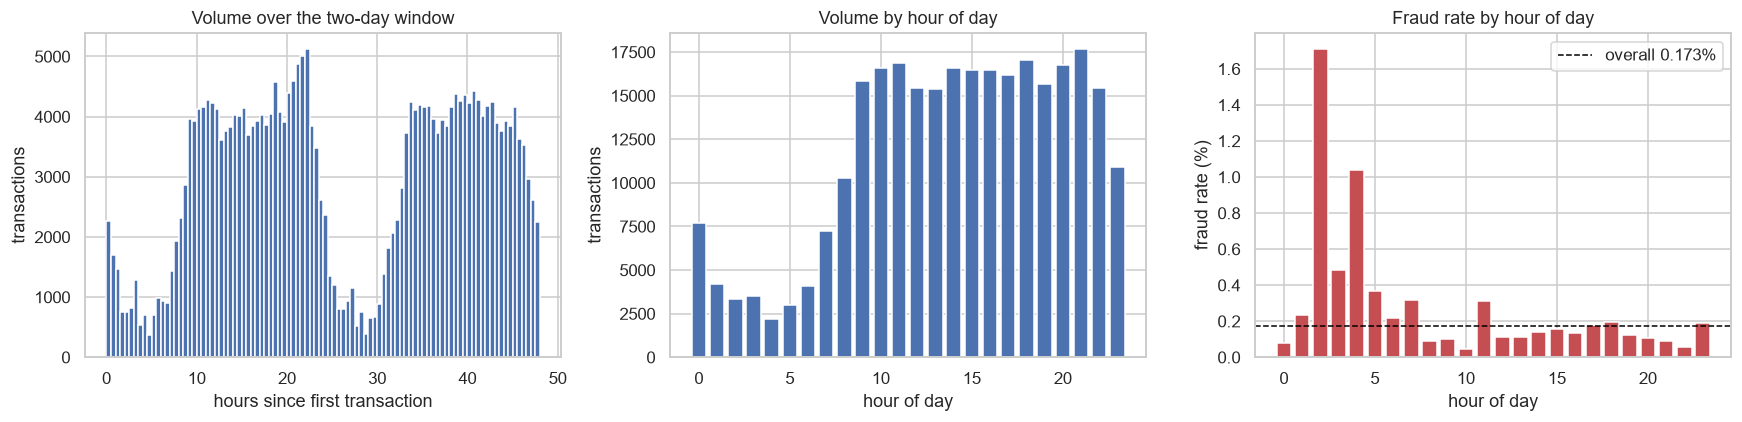


             transactions  frauds  fraud_rate
hour_of_day                                  
0                    7695       6       0.078
1                    4220      10       0.237
2                    3328      57       1.713
3                    3492      17       0.487
4                    2209      23       1.041
5                    2990      11       0.368
6                    4101       9       0.219
7                    7243      23       0.318
8                   10276       9       0.088
9                   15838      16       0.101
10                  16598       8       0.048
11                  16856      53       0.314
12                  15420      17       0.110
13                  15365      17       0.111
14                  16570      23       0.139
15                  16461      26       0.158
16                  16453      22       0.134
17                  16166      29       0.179
18                  17039      33       0.194
19                  15649      19

In [5]:
df["hour_of_day"] = (df["Time"] % 86400) / 3600
print(f"Time spans {df['Time'].max() / 3600:.1f} hours ({df['Time'].max() / 86400:.2f} days)")

hourly = df.groupby(df["hour_of_day"].astype(int)).agg(
    transactions=("Class", "size"), frauds=("Class", "sum")
)
hourly["fraud_rate"] = hourly["frauds"] / hourly["transactions"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df["Time"] / 3600, bins=96, color="#4c72b0")
axes[0].set_xlabel("hours since first transaction")
axes[0].set_ylabel("transactions")
axes[0].set_title("Volume over the two-day window")

axes[1].bar(hourly.index, hourly["transactions"], color="#4c72b0")
axes[1].set_xlabel("hour of day")
axes[1].set_ylabel("transactions")
axes[1].set_title("Volume by hour of day")

axes[2].bar(hourly.index, hourly["fraud_rate"] * 100, color="#c44e52")
axes[2].axhline(df["Class"].mean() * 100, color="black", linestyle="--", linewidth=1,
                label=f"overall {df['Class'].mean():.3%}")
axes[2].set_xlabel("hour of day")
axes[2].set_ylabel("fraud rate (%)")
axes[2].set_title("Fraud rate by hour of day")
axes[2].legend()

fig.tight_layout()
fig.savefig(REPORTS / "time_patterns.png", dpi=150, bbox_inches="tight")
plt.show()

print()
print(hourly.assign(fraud_rate=lambda d: (d["fraud_rate"] * 100).round(3)).to_string())

The volume trough is the middle of the night. Note what happens to the fraud *rate* there — the
denominator collapses while fraud keeps happening, so the ratio spikes. That is a genuine signal
and the reason `hour_of_day` is kept as a feature.

## 4. Which PCA components separate the classes?

V1–V28 are principal components, published this way for privacy: the original features were
transaction details a bank cannot release. This is a real production constraint rather than a
quirk of the dataset — it means no domain feature engineering is possible, and it means model
explanations will be uninterpretable to a fraud analyst.

The components are linearly uncorrelated *with each other* by construction. That says nothing
about their relationship to the label, which is what matters here.

**Correlations below are computed on the training split only.** Using all 284,807 rows would leak
test-set information into a decision (which components get interaction terms) that feeds the model.

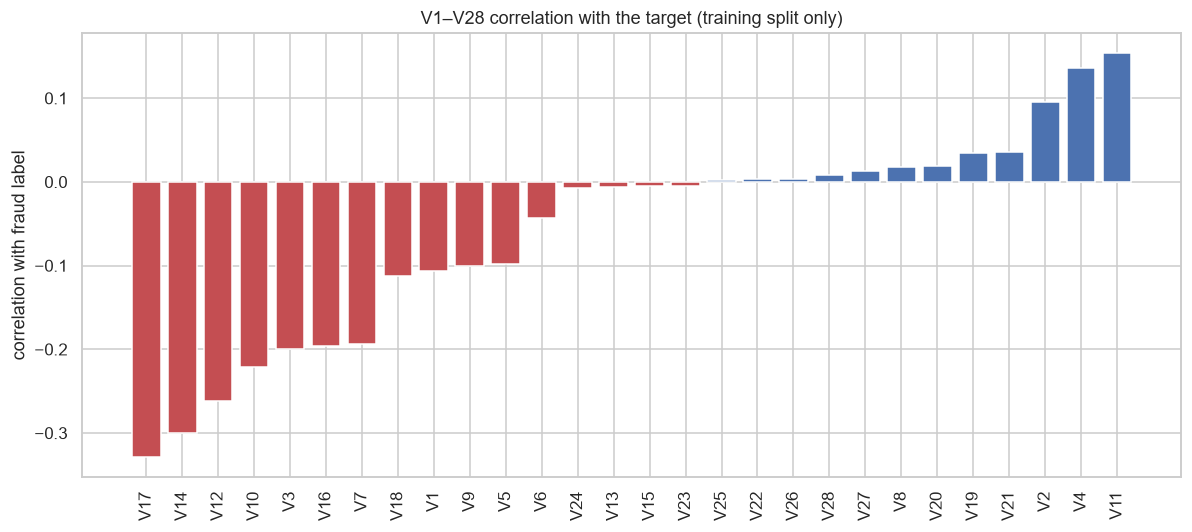

strongest separators (|correlation|):
   V17  -0.329
   V14  -0.300
   V12  -0.262
   V10  -0.221
    V3  -0.199
   V16  -0.196
    V7  -0.194
   V11  +0.154


In [6]:
splits = make_splits(df.drop(columns=["hour_of_day"]))
train = splits.X_train.copy()
train["Class"] = splits.y_train

v_cols = [f"V{i}" for i in range(1, 29)]
corr = train[v_cols + ["Class"]].corr()["Class"].drop("Class").sort_values()

fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#c44e52" if v < 0 else "#4c72b0" for v in corr.values]
ax.bar(corr.index, corr.values, color=colors)
ax.set_ylabel("correlation with fraud label")
ax.set_title("V1–V28 correlation with the target (training split only)")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
fig.savefig(REPORTS / "v_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

top = corr.abs().sort_values(ascending=False).head(8)
print("strongest separators (|correlation|):")
for name, value in top.items():
    print(f"  {name:>4}  {corr[name]:+.3f}")

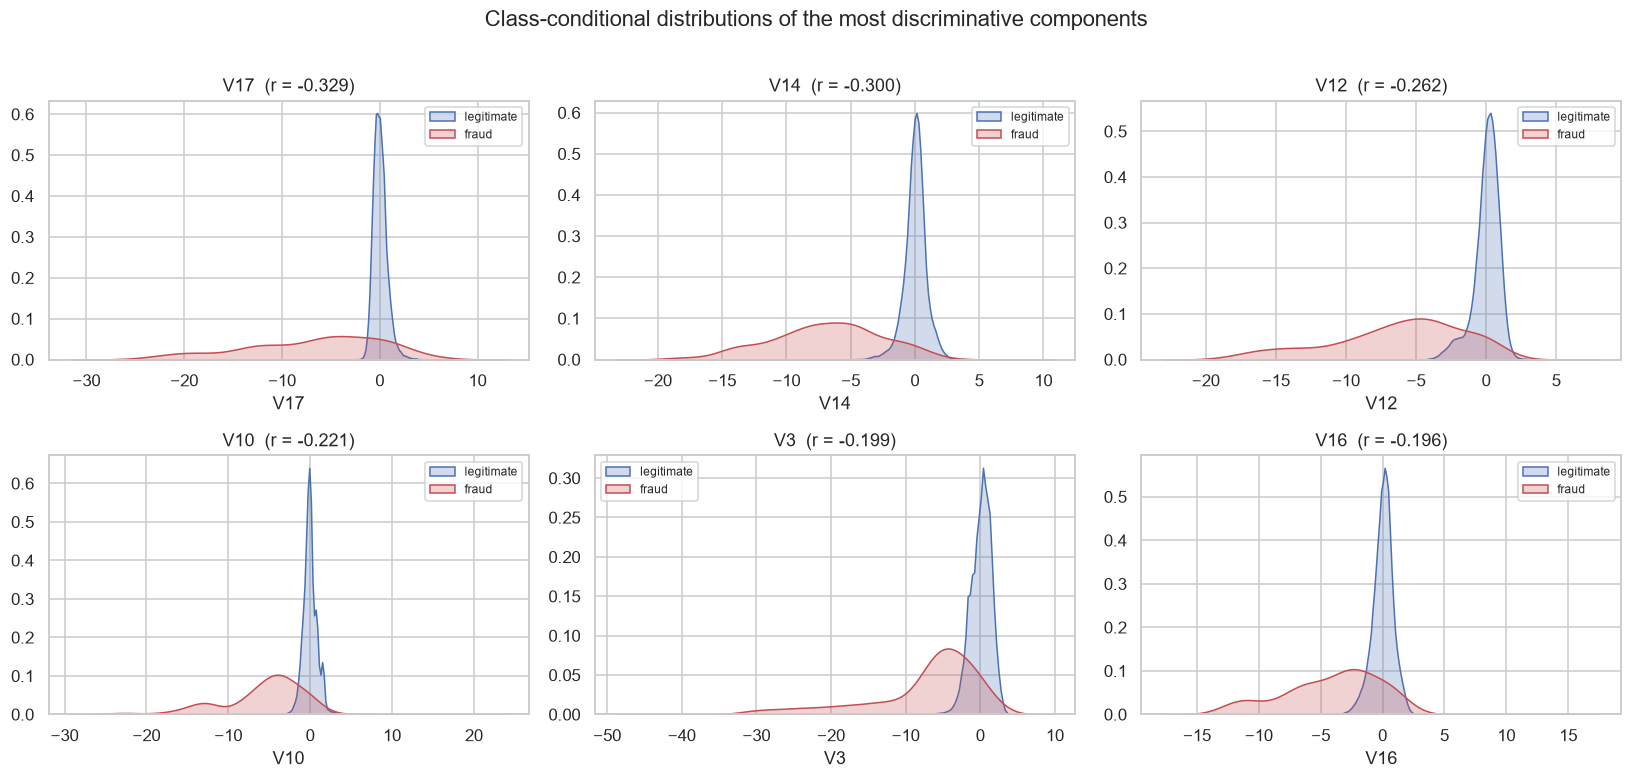

In [7]:
top6 = list(top.head(6).index)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.kdeplot(data=train[train["Class"] == 0], x=col, ax=ax, fill=True,
                label="legitimate", color="#4c72b0", common_norm=False)
    sns.kdeplot(data=train[train["Class"] == 1], x=col, ax=ax, fill=True,
                label="fraud", color="#c44e52", common_norm=False)
    ax.set_title(f"{col}  (r = {corr[col]:+.3f})")
    ax.set_ylabel("")
    ax.legend(fontsize=8)
fig.suptitle("Class-conditional distributions of the most discriminative components", y=1.01)
fig.tight_layout()
fig.savefig(REPORTS / "top_component_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## What this means for the modelling

1. **Accuracy is unusable.** At a 0.172% positive rate, the all-negative classifier scores 99.83%.
   PR-AUC is the primary metric for everything that follows; ROC-AUC is reported but treated as
   secondary, because the 284,315 true negatives inflate it.

2. **The splits must be stratified.** 492 positives split three ways leaves roughly 74 frauds in
   validation. An unstratified draw can swing that number badly, and every metric moves with it.

3. **Feature engineering is confined to `Time` and `Amount`.** `Amount` is log-transformed;
   `Time` becomes hour-of-day and the raw column is dropped. The PCA components admit no domain
   engineering at all — only interactions, built from the components above.

4. **Several components separate the classes cleanly.** The KDE plots show visible separation on
   the strongest ones, which is why even a linear baseline should do respectably here, and why the
   interesting question is how much a tuned tree model adds on top.

5. **Amount is not a strong separator on its own,** but it dominates the *cost* of a mistake —
   which is what makes the threshold analysis in Phase 6 worth doing.
